# Intestine: tissue layers from a single ECM marker (Figure 2)

This notebook reproduces Figure 2 of the paper. It recovers the layers of the human small-intestine wall from one
extracellular-matrix (ECM) marker, collagen IV, without any cellular measurement.

- **Data:** two CODEX images of human small intestine from two donors (HuBMAP). Each has a manual annotation of
  its layers, used only for scoring.
- **Analysis:** collagen IV patches, CNN patch features, an ECM graph, then GraphMAE. These are compared with
  intensity baselines, graph controls and three other spatial methods (BANKSY, UTAG, CellCharter).
- **Run time:** about 30 minutes on one CUDA GPU with 12 GB of memory (the fits use up to 10 GB), or about 80
  minutes on Google Colab's free T4 GPU. All models are trained from scratch with the paper's selected settings.

How the notebook is organised:

| Section | Content |
|---|---|
| 1 | Load the images and cut them into ECM patches |
| 2 | **The method, one step at a time**: every Mantpy call written out for one image and one seed |
| 3 to 5 | The paper's panels: the same steps repeated over images, seeds, graph controls and other methods |
| 6 | The paper's results beside the results of this notebook |

The Mantpy functions used:

| Step | Mantpy function |
|---|---|
| ECM patches | `mt.pp.image_ecm_patches` |
| CNN patch features | `mt.nn.encode_patches` |
| ECM graph and its controls | `mt.gr.build_patch_graph`, `mt.gr.patch_graph_control` |
| Graph embedding | `mt.nn.encode_graphmae` |
| Score against the annotation | `mt.tl.score_patch_labels` |
| Maps | `mt.pl.patch_map` |

Requires `mantpy[patch,gnn]` 1.3.0 or newer and the packages in `intestine_requirements.txt`. Keep
`intestine_helpers.py` and `intestine_selected.json` beside this notebook. For a new analysis, section 2 is all
you need. The helper file holds what is specific to reproducing the paper: loading the two images, the fitting
recipe of the repeated runs, the three external methods, and the rows of maps. Each of its functions takes
everything it uses as an argument.

In [1]:
# Google Colab only: fetch this repository and install the packages. Skipped on your own computer.
# After installing, the runtime restarts so that the installed versions are the ones in use. Colab reports
# this as a crashed session, which is expected: choose Runtime > Run all again.
import os, subprocess, sys, time

REVISION = "main"   # the repository revision this notebook was run from

if "google.colab" in sys.modules:
    repository = "/content/mantpy_reproducibility"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "https://github.com/moeghaf/mantpy_reproducibility", repository], check=True)
    subprocess.run(["git", "-C", repository, "checkout", "--quiet", REVISION], check=True)
    os.chdir(f"{repository}/notebooks")
    installed = "/content/intestine_packages_installed"
    if not os.path.exists(installed):
        pip = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "intestine_requirements.txt"],
                             capture_output=True, text=True)
        if pip.returncode != 0:
            raise RuntimeError(pip.stderr[-3000:])
        open(installed, "w").close()
        print("Packages installed. The runtime restarts now: choose Runtime > Run all again.", flush=True)
        time.sleep(2)   # gives the line above time to reach the page
        os.kill(os.getpid(), 9)

In [2]:
import json, logging, time, warnings
from pathlib import Path

# Known messages that would repeat for every model fit are hidden here, each by its text.
# Every other warning is shown.
for message in (
    "adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation",  # see section 6
    r"The '\w+' does not have many workers",               # the patches are already in memory
    r"`isinstance\(treespec, LeafSpec\)` is deprecated",   # raised inside PyTorch Lightning
    "GPU available but not used",                          # CellCharter's mixture model is fitted on the CPU
    r"'\w+' is not a valid key!",                          # raised while squidpy builds its documentation
    "IProgress not found",                                 # only concerns progress bars
):
    warnings.filterwarnings("ignore", message=message)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import torch
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)   # hides "triton not found" (not used here)
import pytorch_lightning   # imported here so that its log level can be set below
import mantpy as mt
from intestine_helpers import (
    load_images, paper_weight_draw, fit_cnn, fit_graphmae, kmeans_domains, intensity_baselines, run_comparator,
    ScoreTable, show_maps,
)

# PyTorch Lightning prints several information lines for every fit. Its warnings and errors are still shown.
for name in ("pytorch_lightning", "lightning_fabric"):
    logging.getLogger(name).setLevel(logging.WARNING)

ALL = json.loads(Path("intestine_selected.json").read_text())      # the paper's selected settings
SETTINGS = ALL["images"]
PAPER = pd.read_excel("../source_data/fig2.xlsx", sheet_name=None)  # the paper's values, one sheet per panel
TITLES = {"intestine1": "Human small intestine 1", "intestine2": "Human small intestine 2"}
LAYER_COLOURS = dict(zip(
    ["Muscularis propria", "Muscularis mucosae", "Submucosa", "Crypts", "Villus"], plt.get_cmap("tab10").colors))
MAP_COLOURS = {**LAYER_COLOURS, "No matched layer": "0.6"}   # a cluster left without a layer is drawn grey
MAP_SEED = {"intestine1": 4, "intestine2": 0}   # the seed drawn in the paper's Fig. 2a, b, e
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
STARTED = time.perf_counter()

if not (hasattr(mt.tl, "score_patch_labels") and hasattr(mt.gr, "patch_graph_control")):
    raise RuntimeError("This notebook needs Mantpy 1.3.0 or newer "
                       "(mt.tl.score_patch_labels and mt.gr.patch_graph_control).")
if DEVICE != "cuda":
    raise RuntimeError("This notebook needs a CUDA GPU; on a CPU its model fits would take many hours.")

# Full float32 precision on the GPU, as in the paper's runs.
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

print("Mantpy", mt.__version__, "| device:", torch.cuda.get_device_name(0))

Mantpy 1.3.0 | device: NVIDIA GeForce RTX 4070 SUPER


## 1. Load both images and divide them into ECM patches

Image 1 (HuBMAP HBM926.SHNZ.594) has five annotated layers; image 2 (HBM735.PSTF.274) has four, because it
contains no muscularis propria. The annotations are used only for scoring.

`mt.pp.image_ecm_patches` clips at the 99th percentile, scales to [0, 1] and keeps the non-overlapping
32 x 32-pixel patches that contain collagen IV signal (the paper's fixed foreground thresholds). Each retained
patch becomes one ECM node. The result is an `AnnData` with one row per patch.

In [3]:
images = load_images()
patches = {}
for key, item in images.items():
    patches[key] = mt.pp.image_ecm_patches(
        item["image"], channel_names=["ColIV"], patch_size=32, clip_percentile=99,
        pixel_thresholds=[SETTINGS[key]["pixel_threshold"]], patch_thresholds=[SETTINGS[key]["patch_threshold"]],
        feature_families=("summary",), sample_id=key, random_state=0,
    )
    print(f"{TITLES[key]}: {patches[key].n_obs:,} ECM patches | " + ", ".join(item["layers"]))

Human small intestine 1: 13,376 ECM patches | Muscularis propria, Muscularis mucosae, Submucosa, Crypts, Villus


Human small intestine 2: 9,449 ECM patches | Villus, Crypts, Muscularis mucosae, Submucosa


## 2. The method, one step at a time

Image 1, training seed 0, with the settings selected in the paper. Sections 3 to 5 repeat exactly these steps for
both images, more seeds and the control graphs.

**Step 1: CNN patch features.** A small convolutional network learns a 96-number description of each patch
without labels (contrastive learning). The features are written to `obsm["X_cnn"]`.

In [4]:
image1 = patches["intestine1"].copy()

mt.nn.encode_patches(
    image1, latent_dim=96, conv_blocks=3, conv_width=16, pool_size=2, max_epochs=200,
    random_state=0, accelerator=DEVICE, enable_progress_bar=False, enable_model_summary=False,
)
image1.obsm["X_cnn"].shape

(13376, 96)

**Step 2: ECM graph.** Each patch is joined to its 120 nearest patches. An edge is dropped when less than a
quarter of the straight line between the two patches lies on collagen IV signal. Each edge carries its length and
orientation.

In [5]:
graph = mt.gr.build_patch_graph(
    image1, k=120, continuity_thresh=0.25,
    edge_features=("log_euclidean_distance", "sin_angle2", "cos_angle2"),
    # numerical details of the paper's run
    edge_feature_precision="float64", standardization_scope="directed", standardization_eps=0,
)
print(f"{image1.n_obs:,} patches, {graph.edge_index.shape[1]:,} directed edges")

13,376 patches, 1,822,164 directed edges


**Step 3: GraphMAE.** A graph masked autoencoder hides half of the node features and learns to reconstruct them
from neighbouring patches, so each embedding describes a patch in its tissue context. The embeddings are written
to `obsm["X_graphmae"]`.

In [6]:
mt.nn.encode_graphmae(
    image1, graph_key=graph.graph_key, node_feature_key="X_cnn", key_added="X_graphmae",
    encoder="gine", hidden_dim=128, n_layers=4, mask_ratio=0.5, decoder="graphmae_remask", norm="layernorm",
    mitigation="jk", recon_loss="scaled_cosine", max_epochs=200, lr=1e-3, weight_decay=1e-4, standardize=False,
    random_state=0, accelerator=DEVICE, enable_progress_bar=False,
)
image1.obsm["X_graphmae"].shape

(13376, 128)

**Step 4: domains and their score.** K-means groups the embeddings into as many clusters as annotated layers.
`mt.tl.score_patch_labels` scores a partition against the annotation. It takes one label per patch, or a label
for every pixel, and returns:

- `ari`: the adjusted Rand index (1 = perfect, 0 = chance), counted over the annotated pixels inside the analysed
  patches;
- `matched_labels`: each patch named by the annotated layer its cluster matches best (one cluster per layer);
- `recovery`: the fraction of each annotated layer that falls in its matched cluster (0 if no cluster matches it);
- `reference`: the annotated layer of each patch.

The CNN features alone are scored the same way, to show what the graph adds.

In [7]:
annotation, layers = images["intestine1"]["annotation"], images["intestine1"]["layers"]

domains = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(image1.obsm["X_graphmae"])
score = mt.tl.score_patch_labels(image1, domains, annotation, class_names=layers)

cnn_clusters = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(image1.obsm["X_cnn"])
cnn_score = mt.tl.score_patch_labels(image1, cnn_clusters, annotation, class_names=layers)

paper = PAPER["a_seeds"].query("seed == 0").set_index("method")["ari"]
pd.DataFrame({"ARI, this run": [cnn_score.ari, score.ari],
              "ARI, paper (seed 0)": [paper["CNN K-means"], paper["GraphMAE"]]},
             index=["CNN K-means", "GraphMAE"]).round(3)

,"ARI, this run","ARI, paper (seed 0)"
CNN K-means,0.461,0.461
GraphMAE,0.870,0.870


**Step 5: map.** `mt.pl.patch_map` draws one label per patch on the patch grid; here, each patch's matched layer.

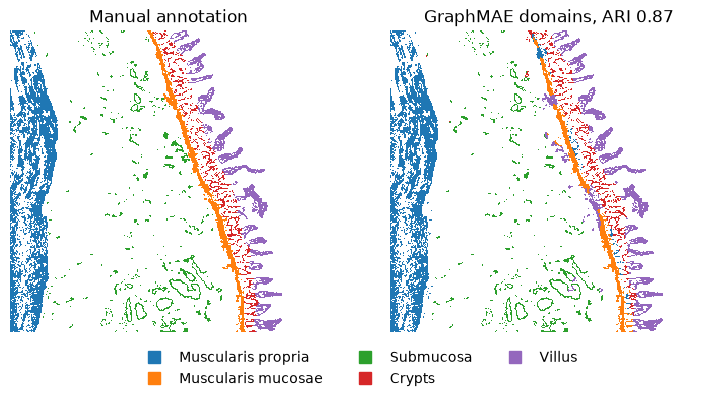

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(9, 5.6))
mt.pl.patch_map(image1, score.reference, ax=axes[0], palette=LAYER_COLOURS, crop=False, background="white")
mt.pl.patch_map(image1, score.matched_labels, ax=axes[1], palette=LAYER_COLOURS, crop=False, background="white",
                legend=dict(bbox_to_anchor=(-0.1, -0.02), ncol=3))
axes[0].set_title("Manual annotation")
axes[1].set_title(f"GraphMAE domains, ARI {score.ari:.2f}")
for axis in axes:
    axis.set_axis_off()
plt.show()

## 3. Three levels of spatial context (Figure 2a, b)

1. **Pixel K-means**: intensity only (scikit-learn, fitted on two million sampled pixels).
2. **CNN K-means**: each patch on its own.
3. **GraphMAE**: each patch with its neighbours on the ECM graph (120 neighbours in image 1, 160 in image 2).

From here on, the steps of section 2 are called through three functions of `intestine_helpers.py`, so that every
run of the paper uses one recipe:

- `fit_cnn` is step 1. The paper's runs drew the network's starting weights once (seeds 0 to 3 of Fig. 2a, b, d)
  or twice (seed 4, and all of Fig. 2c); `paper_weight_draw` returns which, and
  `intestine_helpers.selected_backbone` explains the difference. A new analysis does not need this.
- `fit_graphmae` is steps 2 and 3, with an optional control graph.
- `kmeans_domains` is the K-means of step 4.

`scores` collects the ARI of every partition scored in this notebook.

In [9]:
scores = ScoreTable(patches, images)   # .add(image, panel, method, seed, labels) scores one partition
K = {key: SETTINGS[key]["k"] for key in images}   # clusters = annotated layers: 5 and 4

# Fig. 2a, b, d: the CNN and GraphMAE selected together in the paper.
JOINT_CNN = {key: {name: SETTINGS[key]["joint"]["cnn_" + name] for name in ("blocks", "width", "readout", "activation")}
             for key in images}
JOINT_NEIGHBOURS = {key: SETTINGS[key]["joint"]["neighbours"] for key in images}
JOINT_GRAPHMAE = dict(
    encoder="gine", hidden_dim=128, n_layers=4, mask_ratio=0.5, decoder="graphmae_remask", norm="layernorm",
    mitigation="jk", recon_loss="scaled_cosine", max_epochs=200, lr=1e-3, weight_decay=1e-4, standardize=False,
)
JOINT_KMEANS = dict(threads=2, **ALL["kmeans"]["joint"])   # one K-means seed for every training seed

**Intensity baselines** (single runs). Patch-mean K-means and Multi-Otsu are two further intensity baselines used
in Fig. 2c.

In [10]:
shown = {key: {} for key in images}   # the scores drawn as maps
for key, item in images.items():
    baselines = intensity_baselines(item["image"], patches[key], K[key], SETTINGS[key]["clip"])
    for method, labels in baselines.items():
        score = scores.add(key, "c, baseline", method, 0, labels)
        if method == "Pixel K-means":
            shown[key][method] = score

**CNN and GraphMAE for the seed shown in the paper's maps** (seed 4 in image 1, seed 0 in image 2). The other
seeds follow in section 4.

In [11]:
features = {}   # CNN features by (image, seed), reused in sections 4 and 5
for key in images:
    t = time.perf_counter()
    seed = MAP_SEED[key]
    features[key, seed] = fit_cnn(patches[key], JOINT_CNN[key], seed, draw=paper_weight_draw("joint", seed),
                                  max_epochs=200, device=DEVICE)
    embedding = fit_graphmae(patches[key], features[key, seed], seed, neighbours=JOINT_NEIGHBOURS[key],
                             model=JOINT_GRAPHMAE, device=DEVICE)
    shown[key]["CNN K-means"] = scores.add(key, "d", "CNN K-means", seed,
                                           kmeans_domains(features[key, seed], K[key], **JOINT_KMEANS))
    shown[key]["GraphMAE"] = scores.add(key, "d", "GraphMAE, full graph", seed,
                                        kmeans_domains(embedding, K[key], **JOINT_KMEANS))
    print(f"{TITLES[key]}, seed {seed}: {time.perf_counter() - t:.0f} s", flush=True)

Human small intestine 1, seed 4: 68 s


Human small intestine 2, seed 0: 59 s


In [12]:
# This run against the paper, for the seed shown (source data: sheets a_seeds, b_seeds and c_ari).
rows = {}
for key, sheet in (("intestine1", "a_seeds"), ("intestine2", "b_seeds")):
    paper = PAPER[sheet].query("shown_in_map").set_index("method")["ari"]
    pixel = PAPER["c_ari"].query("image == @TITLES[@key] and method == 'Pixel K-means'")["ari_mean"].item()
    rows[f"{TITLES[key]} (seed {MAP_SEED[key]})"] = pd.DataFrame({
        "spatial context": ["none", "patch", "patch + neighbours"],
        "ARI, this run": [score.ari for score in shown[key].values()],
        "ARI, paper (same seed)": [pixel, paper["CNN K-means"], paper["GraphMAE"]],
    }, index=list(shown[key]))
pd.concat(rows).round(3)

spatial context  \
Human small intestine 1 (seed 4) Pixel K-means                none   
                                 CNN K-means                 patch   
                                 GraphMAE       patch + neighbours   
Human small intestine 2 (seed 0) Pixel K-means                none   
                                 CNN K-means                 patch   
                                 GraphMAE       patch + neighbours   

                                                ARI, this run  \
Human small intestine 1 (seed 4) Pixel K-means          0.196   
                                 CNN K-means            0.447   
                                 GraphMAE               0.903   
Human small intestine 2 (seed 0) Pixel K-means          0.010   
                                 CNN K-means            0.029   
                                 GraphMAE               0.422   

                                                ARI, paper (same seed)  
Human small intestine 1 (seed 4) Pixel K-means                   0.203  
                                 CNN K-means                     0.447  
                                 GraphMAE                        0.902  
Human small intestine 2 (seed 0) Pixel K-means                   0.010  
                                 CNN K-means                     0.029  
                                 GraphMAE                        0.423

### Maps (Figure 2a, b) and recovery of each layer

Each map shows `matched_labels`: clusters matched one-to-one to the annotated layers and coloured by their
matched layer, with the same colours in both images. A cluster left without a layer (it shares no annotated pixel
with a free layer) is drawn grey. The table gives the percentage of each annotated layer's pixels that fall in
its matched GraphMAE domain.

,Human small intestine 1,Human small intestine 2
Annotated layer,,
Muscularis propria,100.0,NaN
Muscularis mucosae,80.0,67.0
Submucosa,88.0,88.0
Crypts,80.0,68.0
Villus,96.0,49.0


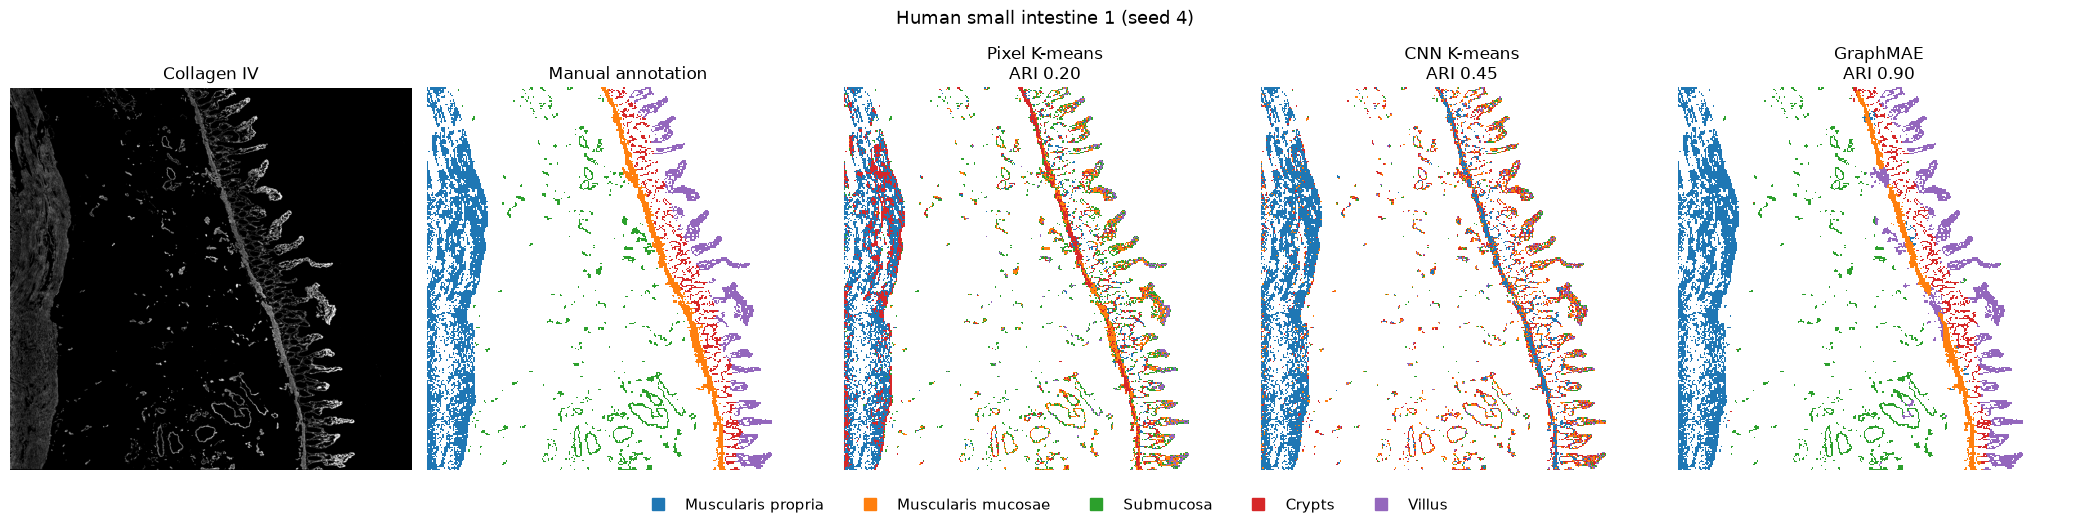

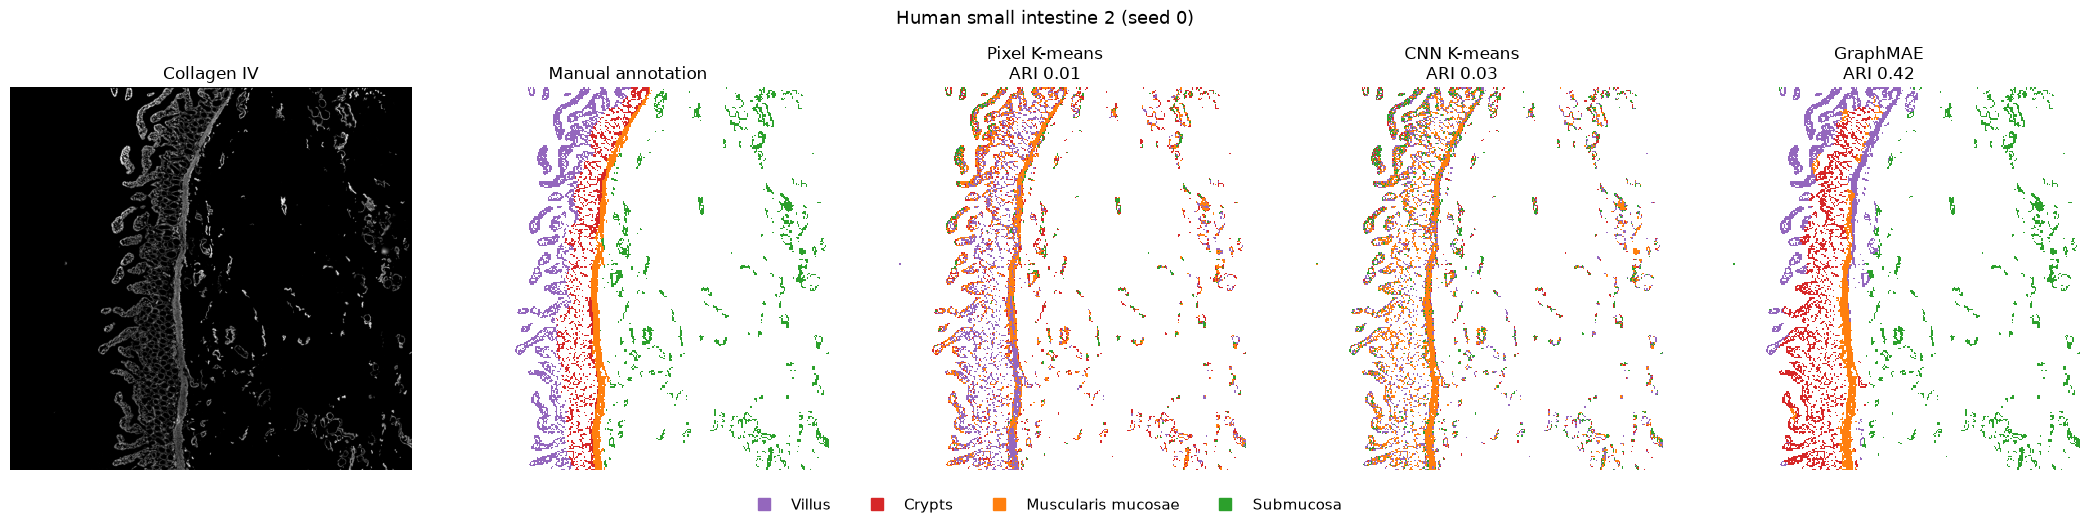

In [13]:
recovery = pd.DataFrame({TITLES[key]: shown[key]["GraphMAE"].recovery * 100 for key in images})
display(recovery.reindex(list(LAYER_COLOURS)).rename_axis("Annotated layer").round(0))
for key, item in images.items():
    clip = SETTINGS[key]["clip"]
    collagen = np.minimum(item["image"][::8, ::8].astype(np.float32), clip) / clip
    show_maps(patches[key], shown[key], item["layers"], f"{TITLES[key]} (seed {MAP_SEED[key]})",
              palette=MAP_COLOURS, collagen=collagen)

### GraphMAE domains (Figure 2e)

Each GraphMAE domain is shown against the other analysed patches (grey), named by its matched layer.

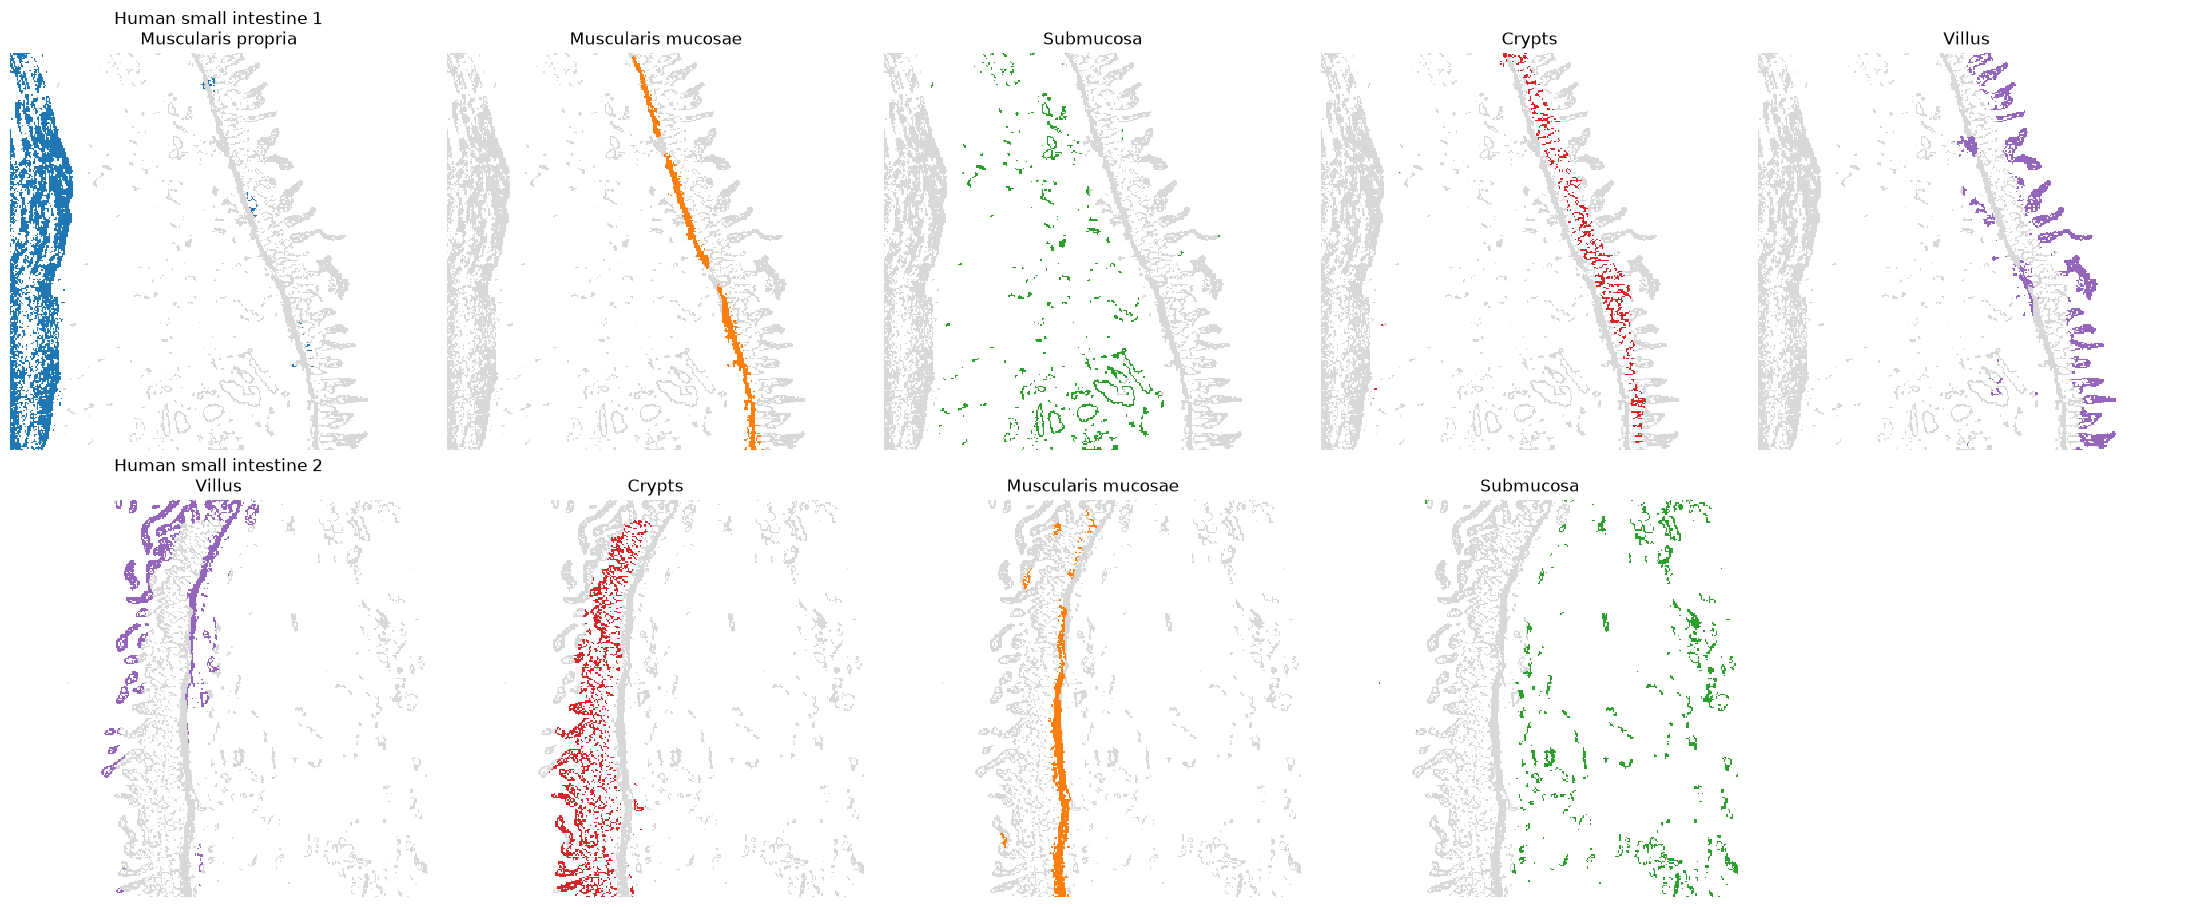

In [14]:
figure, axes = plt.subplots(2, 5, figsize=(22, 9))
for row, (key, item) in enumerate(images.items()):
    matched = shown[key]["GraphMAE"].matched_labels
    for column, (axis, name) in enumerate(zip(axes[row], item["layers"])):
        domain = pd.Series(np.where(matched == name, name, "Other tissue"), index=matched.index)
        mt.pl.patch_map(patches[key], domain, ax=axis, palette={name: LAYER_COLOURS[name], "Other tissue": "0.85"},
                        crop=False, background="white")
        axis.set_title(f"{TITLES[key]}\n{name}" if column == 0 else name, fontsize=12)
for axis in axes.ravel():
    axis.set_axis_off()
figure.tight_layout(h_pad=3)
plt.show()

## 4. Graph controls and five training seeds (Figure 2d)

For each image and each of five training seeds, the same GraphMAE is refitted on the same CNN features on the
two control graphs from `mt.gr.patch_graph_control`: every edge's destination shuffled, and all edges removed.
The CNN and full-graph fits of the remaining seeds are added here, giving the five-seed means quoted for
Fig. 2a, b. K-means uses the same initialisation seed for every training seed in these panels, as in the paper's
runs.

In [15]:
CONTROLS = {"GraphMAE, shuffled edges": "shuffled_edges", "GraphMAE, no edges": "no_edges"}
for key in images:
    for seed in ALL["seeds"]["joint"]:
        t = time.perf_counter()
        if (key, seed) not in features:     # the seed shown in the maps was fitted in section 3
            features[key, seed] = fit_cnn(patches[key], JOINT_CNN[key], seed, draw=paper_weight_draw("joint", seed),
                                          max_epochs=200, device=DEVICE)
            embedding = fit_graphmae(patches[key], features[key, seed], seed, neighbours=JOINT_NEIGHBOURS[key],
                                     model=JOINT_GRAPHMAE, device=DEVICE)
            scores.add(key, "d", "CNN K-means", seed, kmeans_domains(features[key, seed], K[key], **JOINT_KMEANS))
            scores.add(key, "d", "GraphMAE, full graph", seed, kmeans_domains(embedding, K[key], **JOINT_KMEANS))
        for method, control in CONTROLS.items():
            embedding = fit_graphmae(patches[key], features[key, seed], seed, neighbours=JOINT_NEIGHBOURS[key],
                                     model=JOINT_GRAPHMAE, control=control, device=DEVICE)
            scores.add(key, "d", method, seed, kmeans_domains(embedding, K[key], **JOINT_KMEANS))
        print(f"{TITLES[key]}, seed {seed}: {time.perf_counter() - t:.0f} s", flush=True)

Human small intestine 1, seed 0: 116 s


Human small intestine 1, seed 1: 124 s


Human small intestine 1, seed 2: 121 s


Human small intestine 1, seed 3: 120 s


Human small intestine 1, seed 4: 46 s


Human small intestine 2, seed 0: 44 s


Human small intestine 2, seed 1: 106 s


Human small intestine 2, seed 2: 102 s


Human small intestine 2, seed 3: 99 s


Human small intestine 2, seed 4: 100 s


Mean ± s.d. over the five seeds against the paper (source data: sheet `d_means`), then every seed.

In [16]:
ORDER_D = ["CNN K-means", "GraphMAE, shuffled edges", "GraphMAE, no edges", "GraphMAE, full graph"]
d = scores.frame().query("panel == 'd'").replace({"image": TITLES})
paper_d = PAPER["d_means"].set_index(["image", "condition"])
rows_d = pd.MultiIndex.from_product([TITLES.values(), ORDER_D], names=["image", "method"])

summary_d = d.groupby(["image", "method"])["ARI"].agg(["mean", "std"]).reindex(rows_d)
display(pd.DataFrame({
    "this run": summary_d["mean"].map("{:.3f}".format) + " ± " + summary_d["std"].map("{:.3f}".format),
    "paper": (paper_d["mean"].map("{:.3f}".format) + " ± " + paper_d["sd"].map("{:.3f}".format)).reindex(rows_d),
}))
display(d.pivot(index=["image", "method"], columns="seed", values="ARI").reindex(rows_d).round(3))

this run          paper
image                   method                                                
Human small intestine 1 CNN K-means               0.451 ± 0.006  0.451 ± 0.006
                        GraphMAE, shuffled edges  0.001 ± 0.001  0.001 ± 0.001
                        GraphMAE, no edges        0.243 ± 0.035  0.243 ± 0.035
                        GraphMAE, full graph      0.897 ± 0.017  0.897 ± 0.017
Human small intestine 2 CNN K-means               0.024 ± 0.004  0.024 ± 0.004
                        GraphMAE, shuffled edges  0.000 ± 0.000  0.000 ± 0.000
                        GraphMAE, no edges        0.039 ± 0.012  0.039 ± 0.012
                        GraphMAE, full graph      0.420 ± 0.027  0.418 ± 0.030

seed                                                  0      1      2      3  \
image                   method                                                 
Human small intestine 1 CNN K-means               0.461  0.445  0.450  0.453   
                        GraphMAE, shuffled edges  0.001  0.003  0.000  0.001   
                        GraphMAE, no edges        0.289  0.244  0.195  0.257   
                        GraphMAE, full graph      0.870  0.903  0.915  0.893   
Human small intestine 2 CNN K-means               0.029  0.022  0.024  0.026   
                        GraphMAE, shuffled edges  0.000  0.000  0.000  0.000   
                        GraphMAE, no edges        0.058  0.027  0.035  0.040   
                        GraphMAE, full graph      0.422  0.431  0.415  0.452   

seed                                                  4  
image                   method                           
Human small intestine 1 CNN K-means               0.447  
                        GraphMAE, shuffled edges  0.001  
                        GraphMAE, no edges        0.231  
                        GraphMAE, full graph      0.903  
Human small intestine 2 CNN K-means               0.019  
                        GraphMAE, shuffled edges  0.001  
                        GraphMAE, no edges        0.034  
                        GraphMAE, full graph      0.379

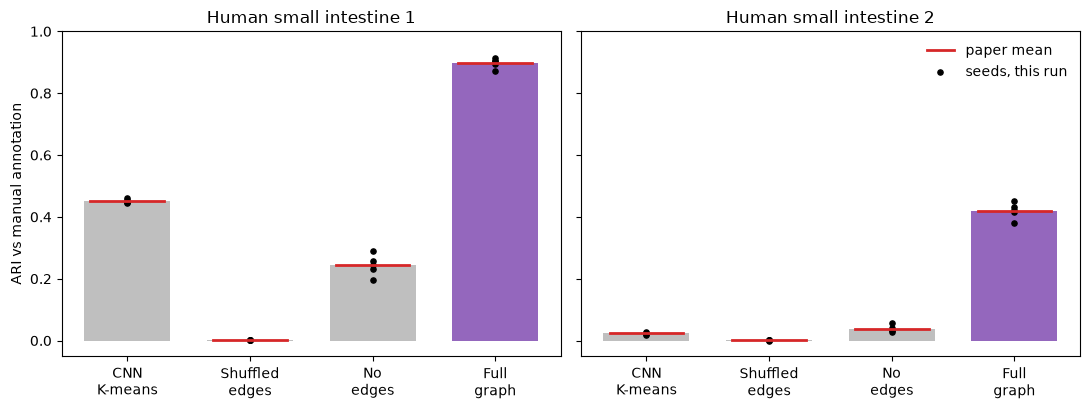

In [17]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for axis, title in zip(axes, TITLES.values()):
    for i, method in enumerate(ORDER_D):
        values = d[(d.image == title) & (d.method == method)]["ARI"].to_numpy()
        axis.bar(i, values.mean(), color="tab:purple" if "full" in method else "0.75", width=0.7)
        axis.scatter(np.full(len(values), i), values, color="black", s=14, zorder=3)
        axis.plot([i - 0.3, i + 0.3], [paper_d.loc[(title, method), "mean"]] * 2, color="tab:red", linewidth=2, zorder=4)
    axis.set_xticks(range(4), ["CNN\nK-means", "Shuffled\nedges", "No\nedges", "Full\ngraph"])
    axis.set_title(title)
    axis.set_ylim(-0.05, 1)
axes[0].set_ylabel("ARI vs manual annotation")
axes[1].plot([], [], color="tab:red", linewidth=2, label="paper mean")
axes[1].scatter([], [], color="black", s=14, label="seeds, this run")
axes[1].legend(frameon=False)
figure.tight_layout()
plt.show()

## 5. Method comparison (Figure 2c)

The same patches and CNN features are analysed by GraphMAE and by BANKSY, UTAG and CellCharter (external
packages). `run_comparator` in `intestine_helpers.py` gives each external method the patch `AnnData` holding the
CNN features and coordinates in micrometres, lets it apply its own neighbourhood transformation, and clusters the
result at the number of annotated layers.

For this comparison the paper chose a CNN independently of GraphMAE (32 channels wide), and all its starting
weights were drawn twice. The GraphMAE in this panel uses a GIN encoder without edge features, two layers and 75%
masking, on 240 (image 1) or 80 (image 2) neighbours, as selected in the paper. K-means is re-seeded with each
training seed.

### Selected settings, three seeds

The CNN and each method's neighbourhood setting were chosen in the paper without the annotation, by seed
stability. Only the selected settings are refitted here. The maps of every method are drawn as each seed
finishes.

  0%|          | 0/4 [00:00<?, ?it/s]

 75%|███████▌  | 3/4 [00:00<00:00,  5.69it/s]

100%|██████████| 4/4 [00:01<00:00,  2.21it/s]

100%|██████████| 4/4 [00:01<00:00,  2.56it/s]

Human small intestine 1, seed 0: 90 s


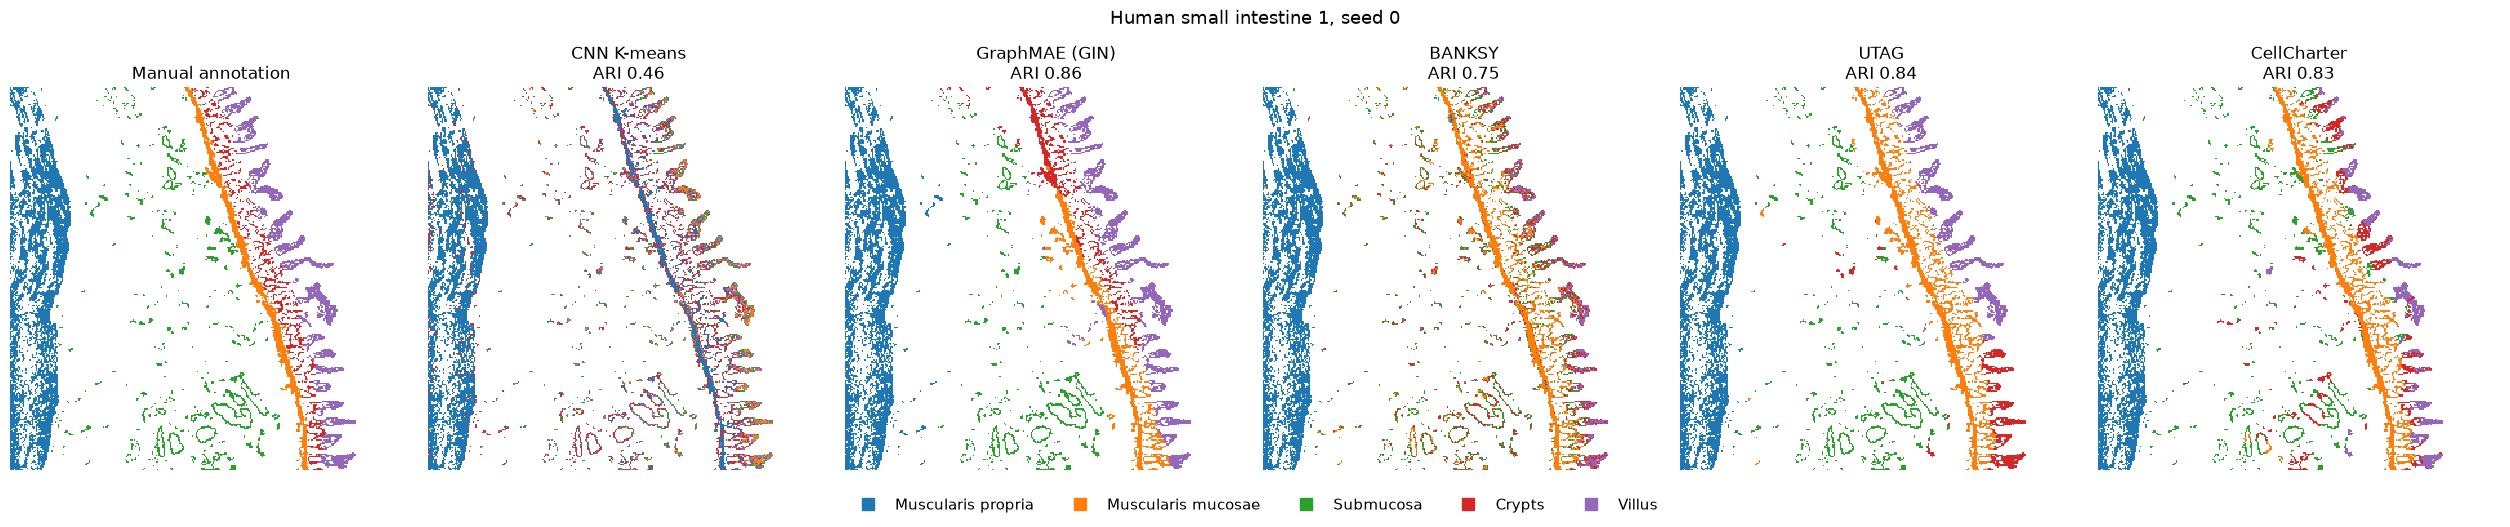

  0%|          | 0/4 [00:00<?, ?it/s]

 75%|███████▌  | 3/4 [00:00<00:00,  5.56it/s]

100%|██████████| 4/4 [00:01<00:00,  2.22it/s]

100%|██████████| 4/4 [00:01<00:00,  2.57it/s]

Human small intestine 1, seed 1: 96 s


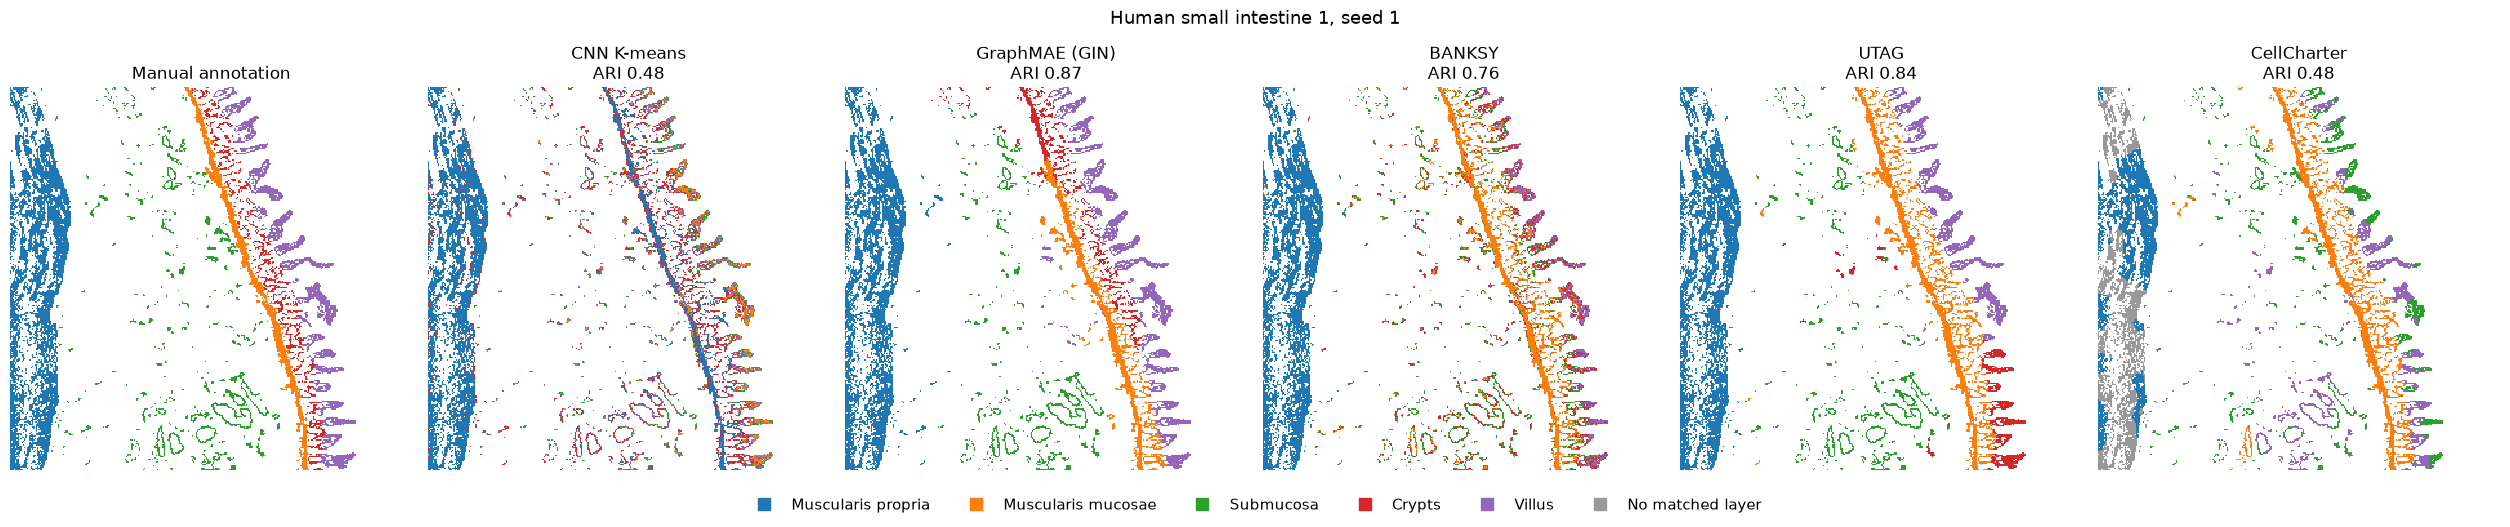

  0%|          | 0/4 [00:00<?, ?it/s]

 75%|███████▌  | 3/4 [00:00<00:00,  5.59it/s]

100%|██████████| 4/4 [00:01<00:00,  2.19it/s]

100%|██████████| 4/4 [00:01<00:00,  2.53it/s]

Human small intestine 1, seed 2: 90 s


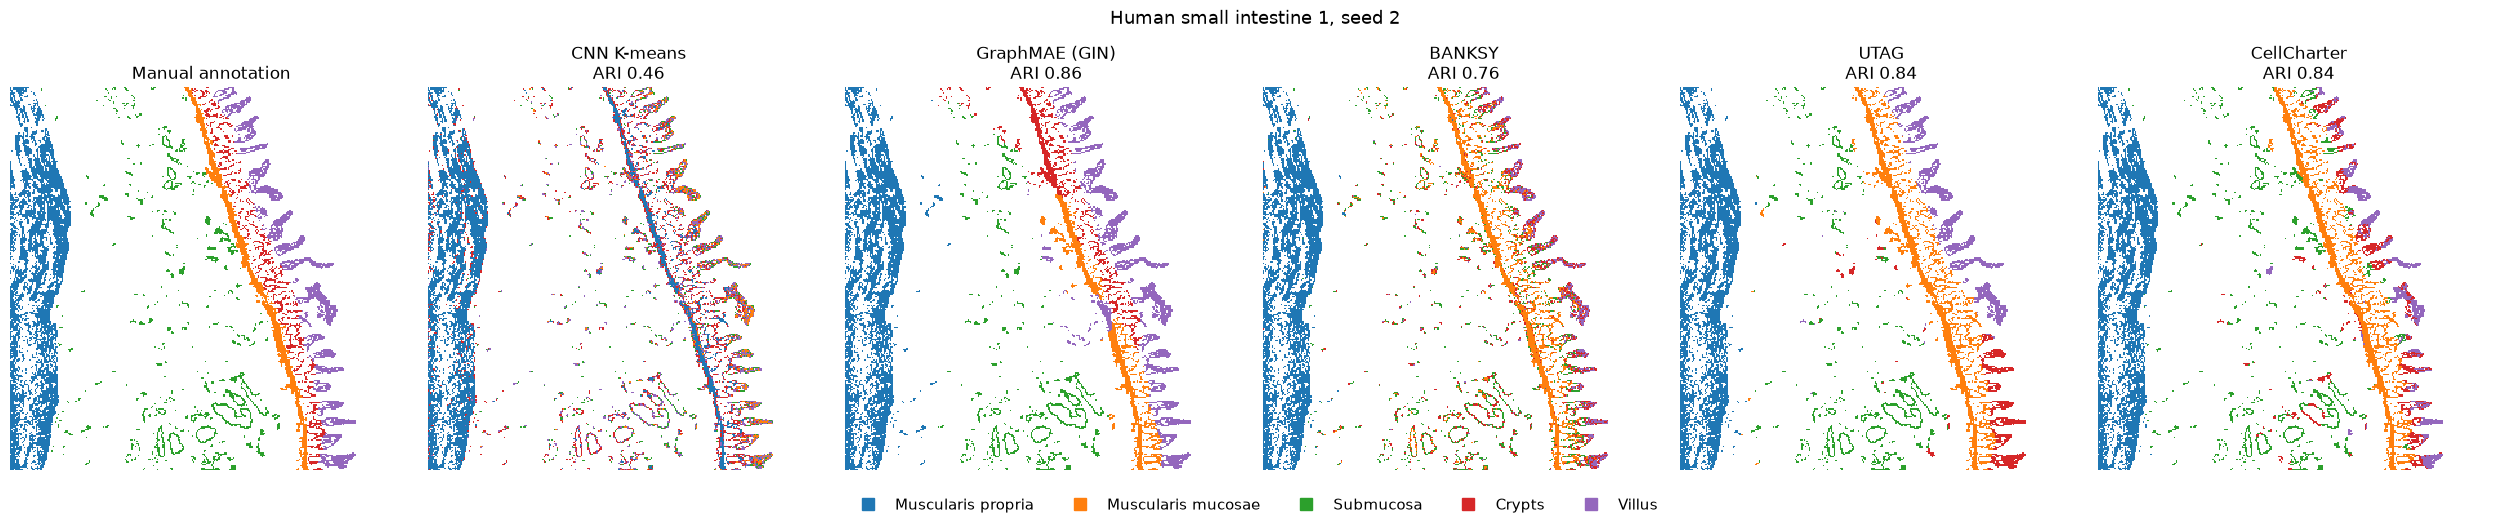

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 168.15it/s]

Human small intestine 2, seed 0: 77 s


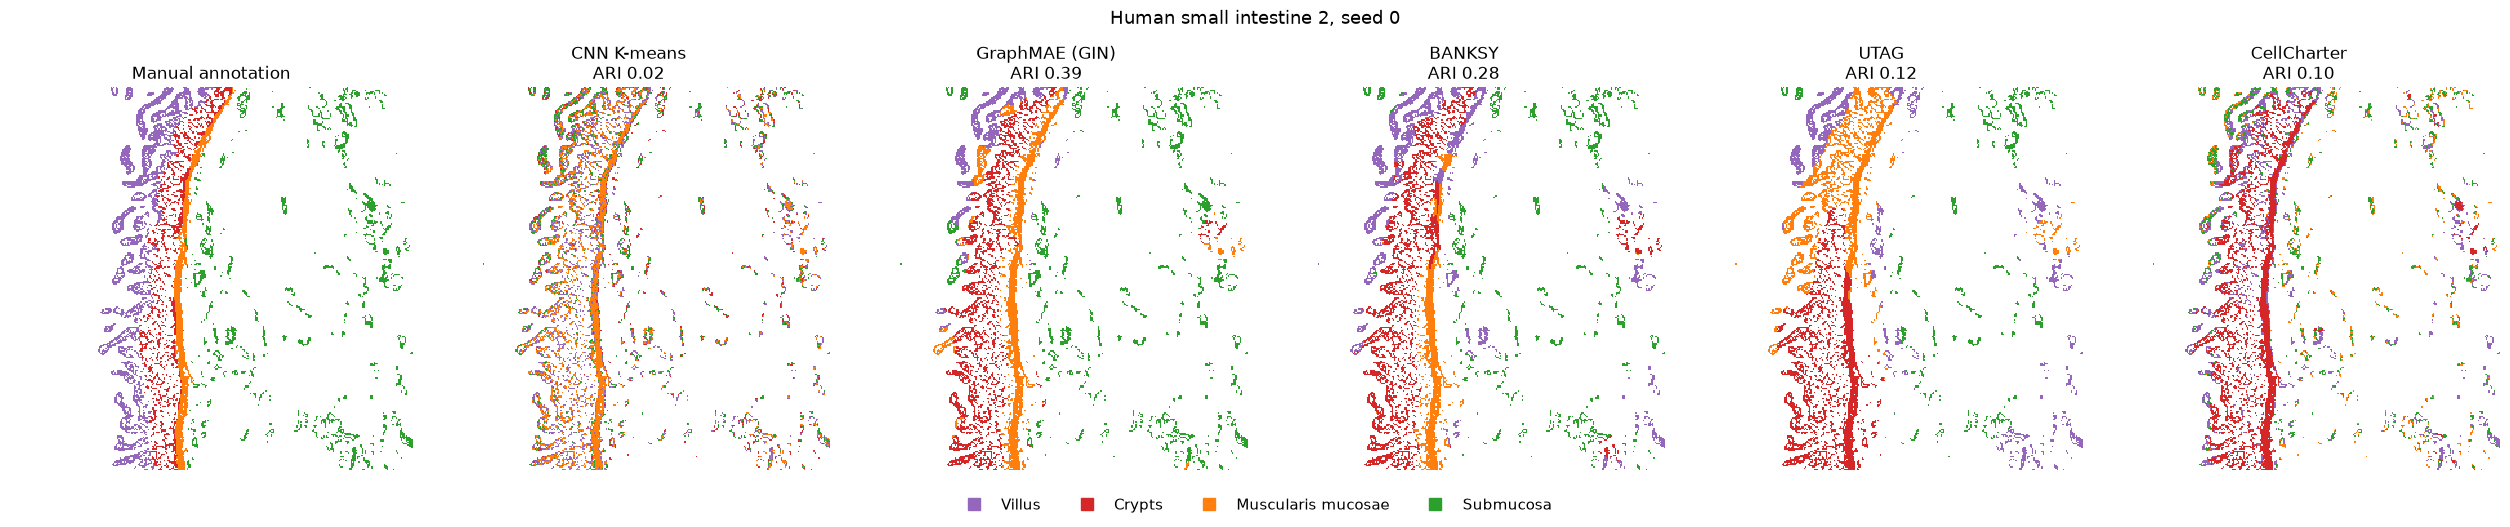

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 156.69it/s]

Human small intestine 2, seed 1: 74 s


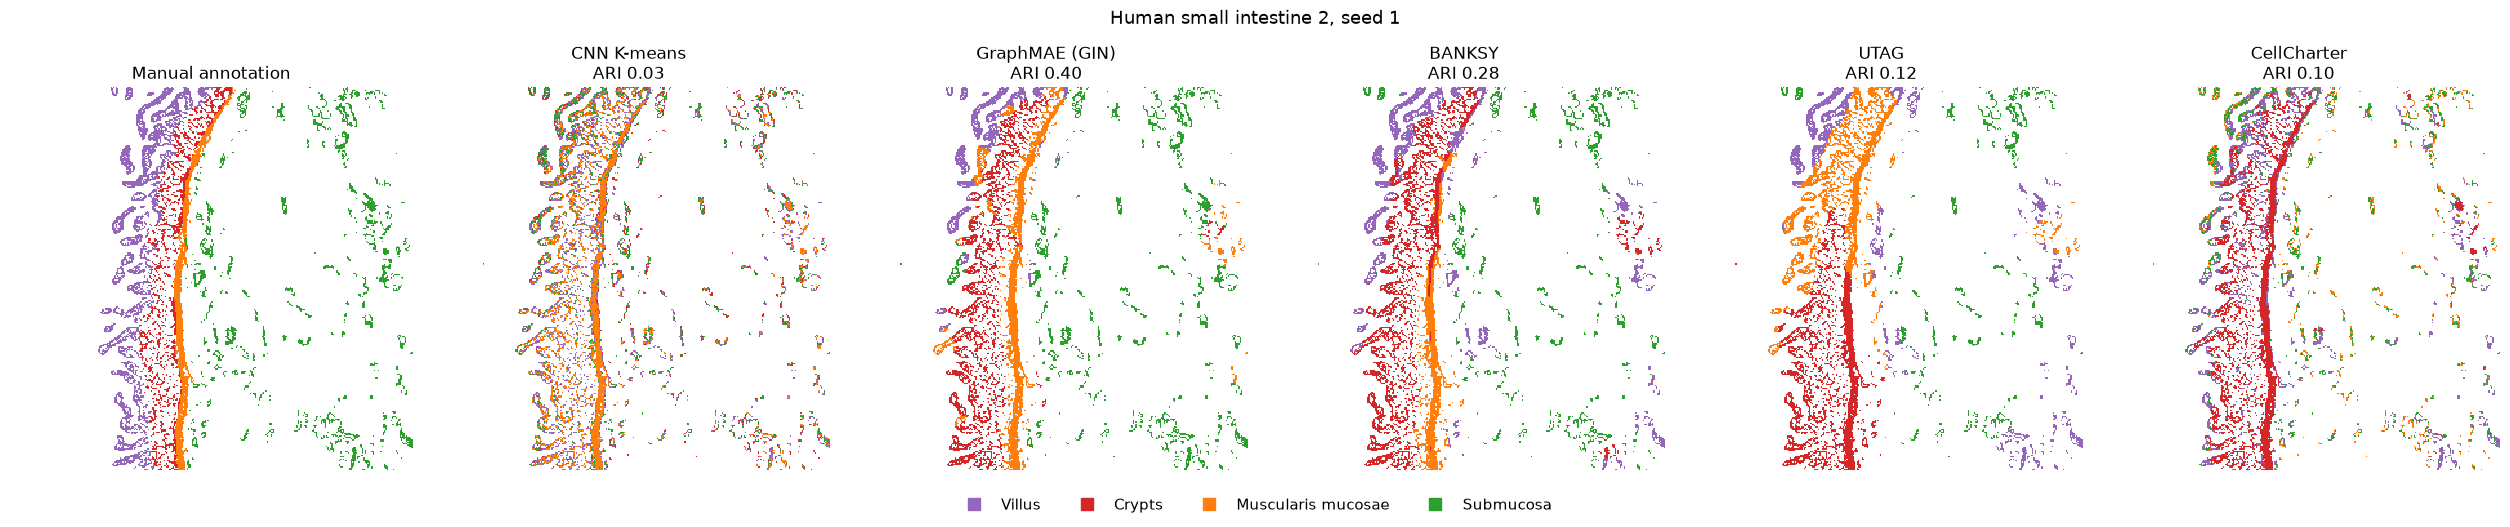

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 115.88it/s]

Human small intestine 2, seed 2: 105 s


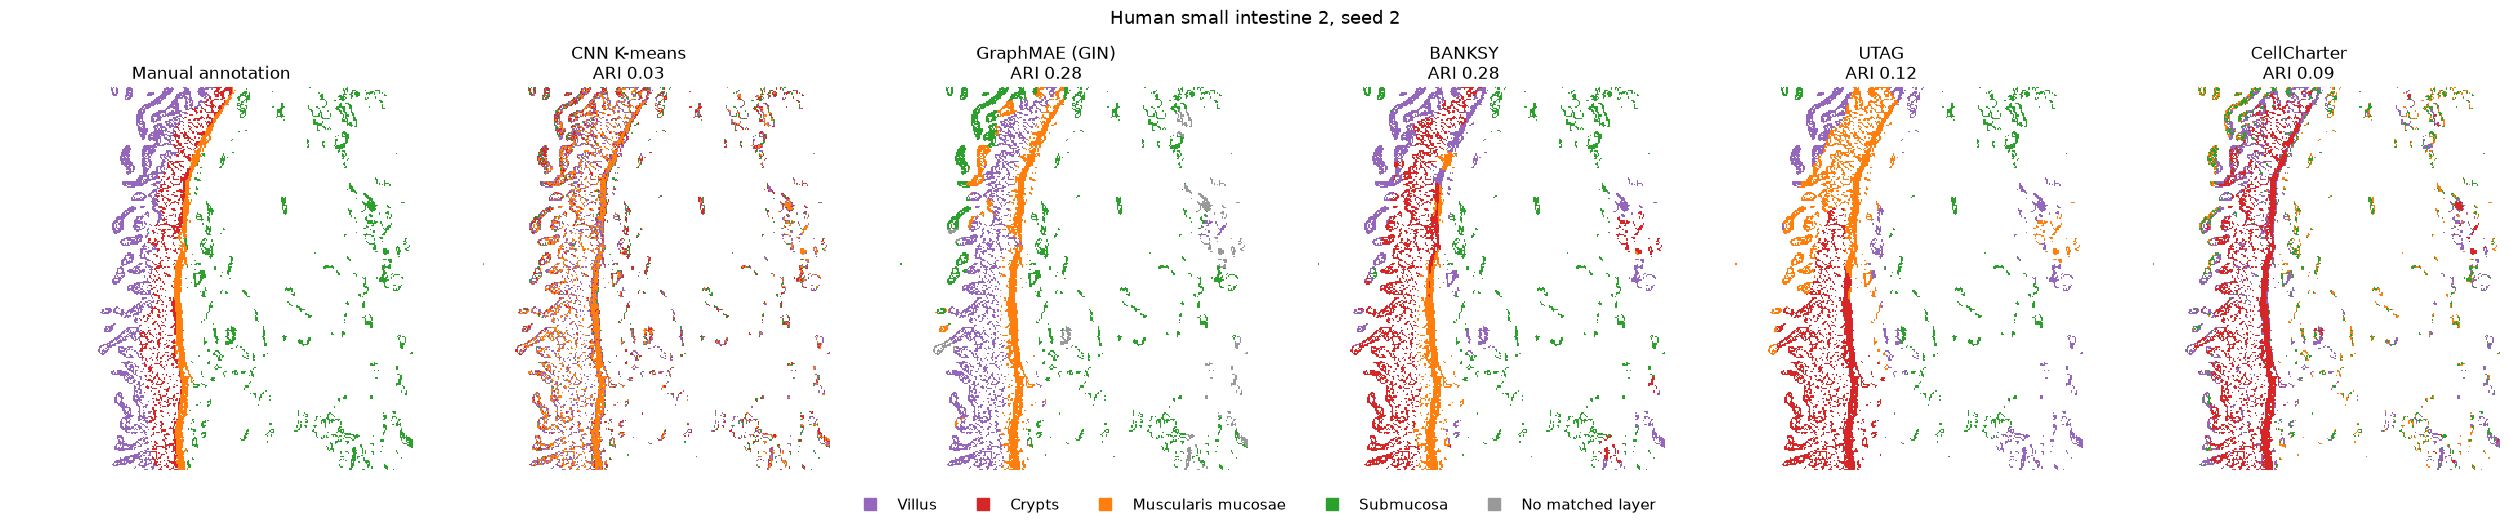

In [18]:
comparison = {}   # seed-0 results, for the overview at the end
for key, item in images.items():
    selected = {name: entry["config"] for name, entry in SETTINGS[key]["matched_methods"].items()}
    model = dict(n_layers=selected["graphmae"]["depth"], mask_ratio=selected["graphmae"]["mask"],
                 **ALL["matched_graphmae_fixed"])
    for seed in ALL["seeds"]["matched"]:
        t = time.perf_counter()
        kmeans = dict(threads=4, random_state=seed, **ALL["kmeans"]["matched"])
        matched = fit_cnn(patches[key], SETTINGS[key]["matched_cnn"]["architecture"], seed,
                          draw=paper_weight_draw("matched", seed), max_epochs=200, device=DEVICE)
        embedding = fit_graphmae(patches[key], matched, seed, neighbours=selected["graphmae"]["k"], model=model,
                                 threads=4, device=DEVICE)
        partitions = {"CNN K-means": kmeans_domains(matched, K[key], **kmeans),
                      "GraphMAE (GIN)": kmeans_domains(embedding, K[key], **kmeans)}
        for name in ("BANKSY", "UTAG", "CellCharter"):
            partitions[name] = run_comparator(name, patches[key], matched, selected[name.lower()],
                                              n_clusters=K[key], seed=seed, n_init=10)
        results = {name: scores.add(key, "c, selected", name, seed, labels) for name, labels in partitions.items()}
        if seed == 0:
            comparison[key] = results
        print(f"{TITLES[key]}, seed {seed}: {time.perf_counter() - t:.0f} s", flush=True)
        show_maps(patches[key], results, item["layers"], f"{TITLES[key]}, seed {seed}", palette=MAP_COLOURS)

### Default settings, single runs

BANKSY, UTAG and CellCharter at their default neighbourhood settings, on the seed-0 CNN features of Fig. 2a, b.

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 93.87it/s]

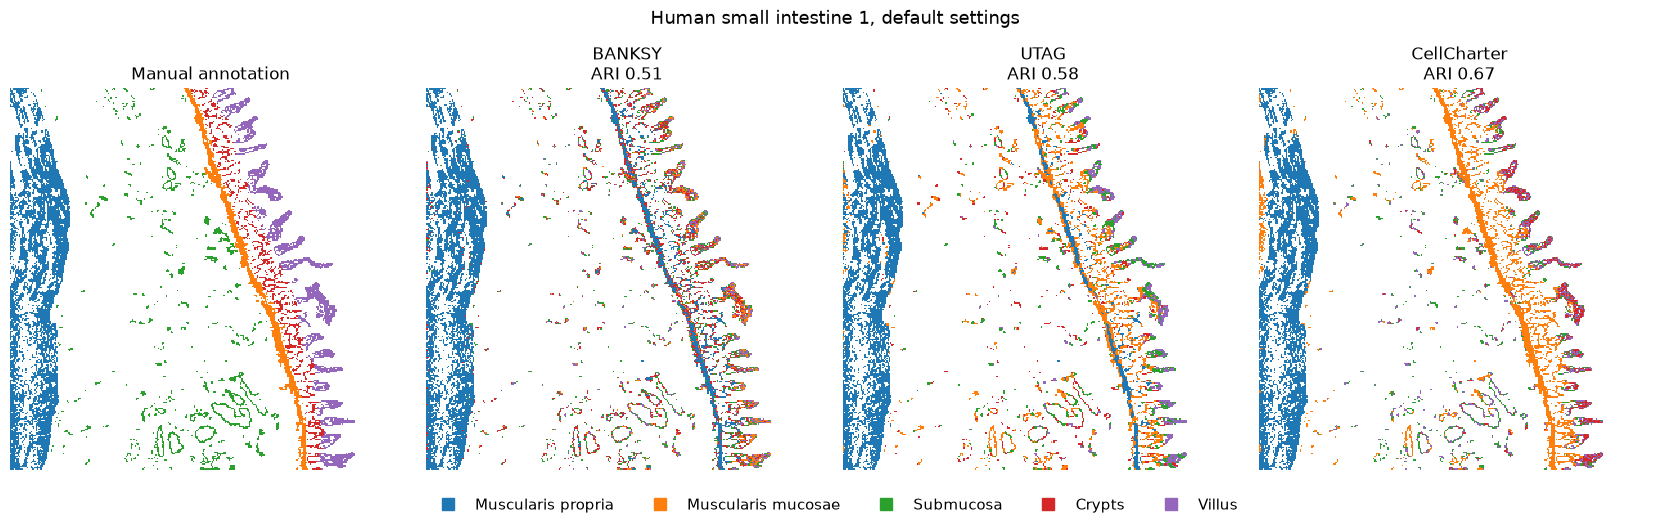

  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 123.45it/s]

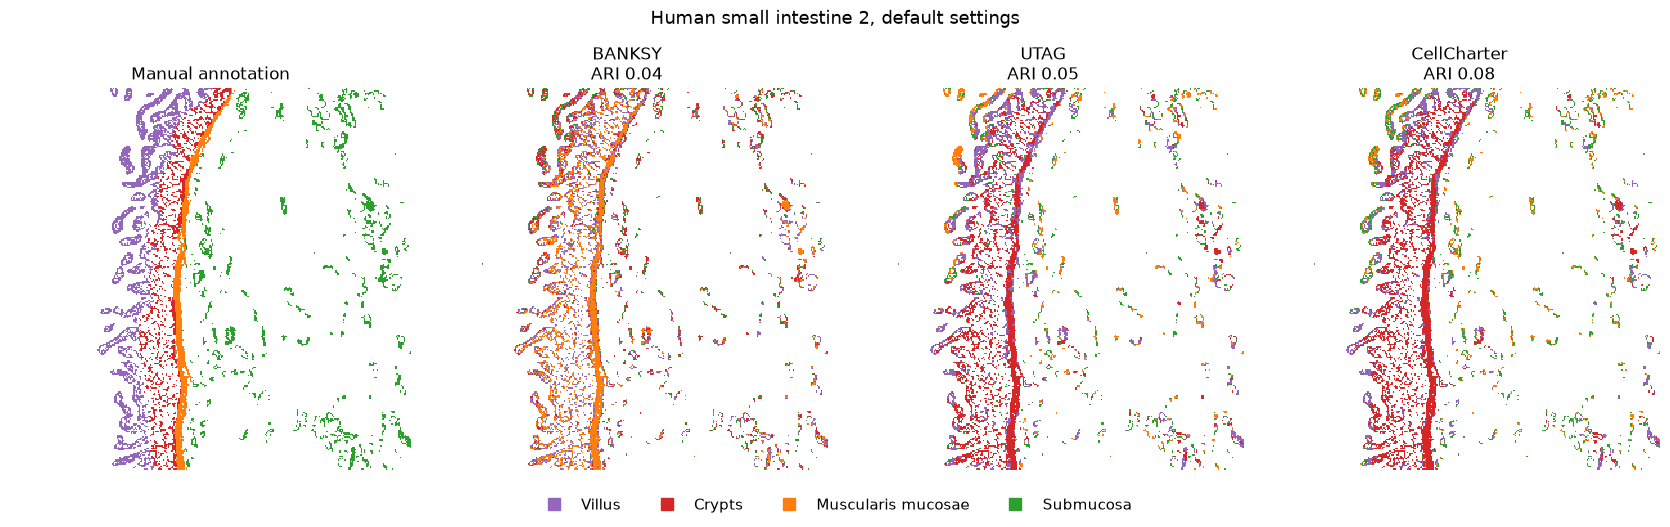

In [19]:
DEFAULTS = {
    "BANKSY": {"k": 15, "lambda": 0.2, "max_m": 1, "pca": 20},
    "UTAG": {"radius_um": 20.0, "pca": 10, "normalization": "l1_norm"},
    "CellCharter": {"graph": "native_knn6", "hops": 3},
}
for key, item in images.items():
    results = {}
    for name, config in DEFAULTS.items():
        labels = run_comparator(name, patches[key], features[key, 0], config, n_clusters=K[key], seed=0, n_init="auto")
        results[name] = scores.add(key, "c, default", name, 0, labels)
    show_maps(patches[key], results, item["layers"], f"{TITLES[key]}, default settings", palette=MAP_COLOURS)

### All methods together

One row per image: every method at its selected settings (seed 0), from no spatial context to the graph methods.

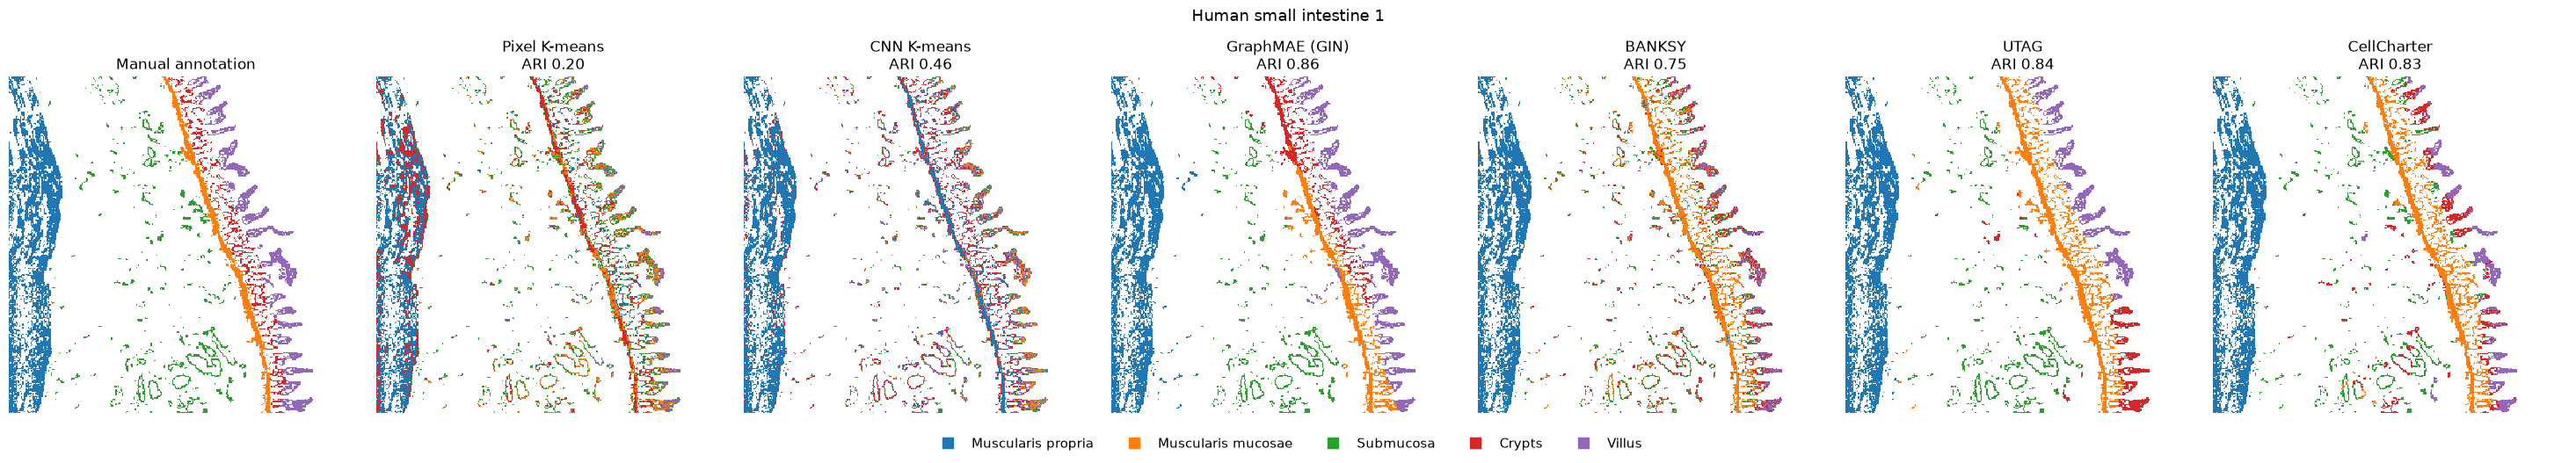

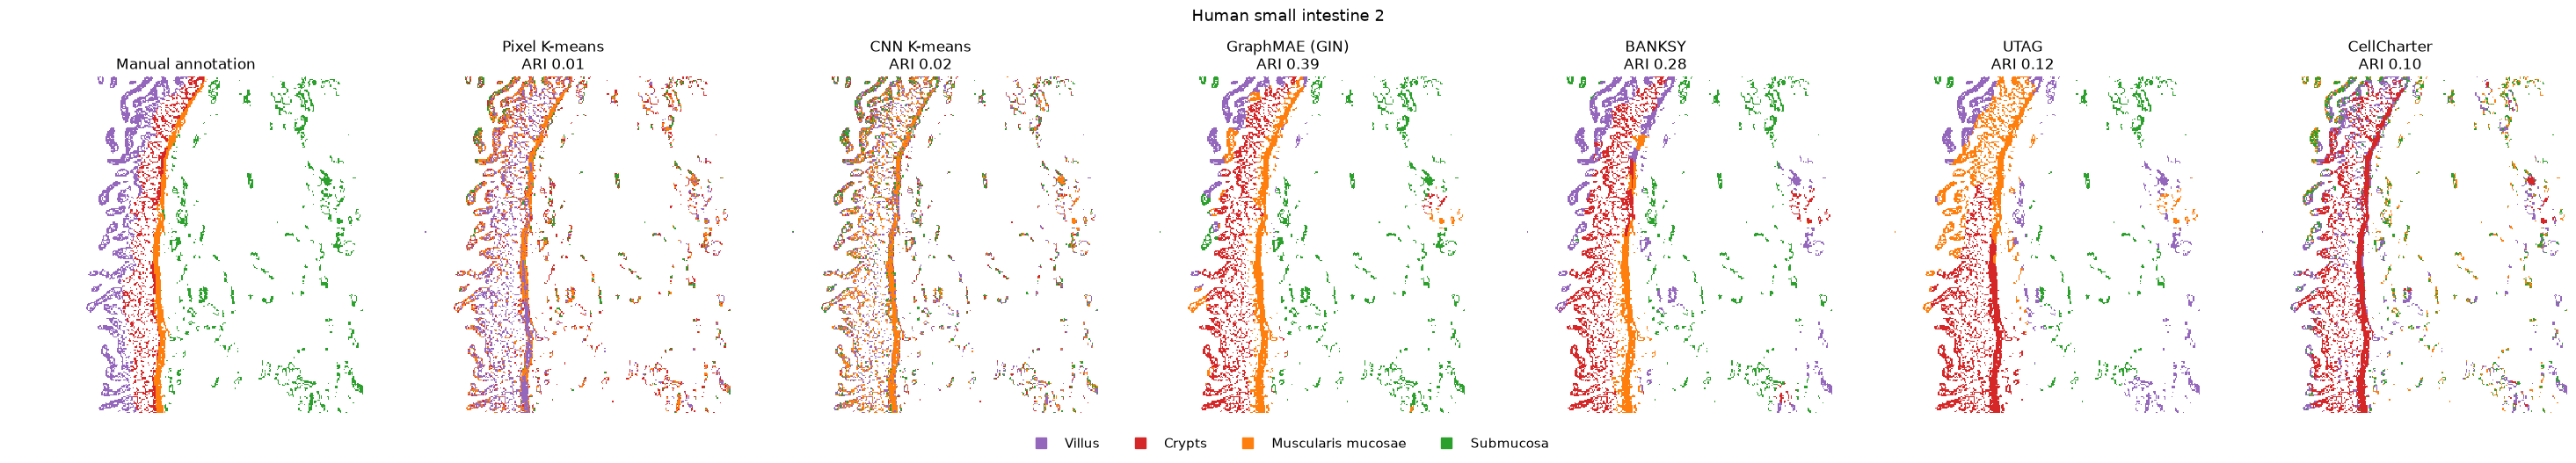

In [20]:
for key, item in images.items():
    show_maps(patches[key], {"Pixel K-means": shown[key]["Pixel K-means"], **comparison[key]}, item["layers"],
              TITLES[key], palette=MAP_COLOURS)

### Scores against the paper (Figure 2c)

Selected settings: mean ± s.d. over three seeds (single runs for the intensity baselines). Paper values are read
from the source data, sheet `c_ari`.

In [21]:
METHODS = ["GraphMAE (GIN)", "UTAG", "BANKSY", "CellCharter", "CNN K-means", "Patch-mean K-means", "Multi-Otsu", "Pixel K-means"]
c = scores.frame().query("panel.str.startswith('c')").replace({"image": TITLES})
paper_c = PAPER["c_ari"].set_index(["image", "method"])


def mean_sd(mean, sd):
    return f"{mean:.3f}" + ("" if pd.isna(sd) else f" ± {sd:.3f}")


rows = []
for title in TITLES.values():
    for method in METHODS:
        ours = c[(c.image == title) & (c.method == method)]
        main, default = ours[ours.panel != "c, default"]["ARI"], ours[ours.panel == "c, default"]["ARI"]
        paper = paper_c.loc[(title, method)]
        rows.append({
            "image": title, "method": method,
            "this run": mean_sd(main.mean(), main.std()),
            "paper": mean_sd(paper["ari_mean"], paper["ari_sd"]),
            "seeds, this run": ", ".join(f"{v:.2f}" for v in main) if len(main) > 1 else "",
            "default, this run": f"{default.iloc[0]:.3f}" if len(default) else "",
            "default, paper": "" if pd.isna(paper["ari_default"]) else f"{paper['ari_default']:.3f}",
        })
pd.DataFrame(rows).set_index(["image", "method"])

this run          paper  \
image                   method                                             
Human small intestine 1 GraphMAE (GIN)      0.864 ± 0.006  0.866 ± 0.004   
                        UTAG                0.843 ± 0.001  0.842 ± 0.004   
                        BANKSY              0.757 ± 0.008  0.753 ± 0.006   
                        CellCharter         0.714 ± 0.206  0.831 ± 0.006   
                        CNN K-means         0.469 ± 0.012  0.473 ± 0.012   
                        Patch-mean K-means          0.229          0.229   
                        Multi-Otsu                  0.222          0.222   
                        Pixel K-means               0.196          0.203   
Human small intestine 2 GraphMAE (GIN)      0.354 ± 0.064  0.389 ± 0.003   
                        UTAG                0.123 ± 0.001  0.123 ± 0.001   
                        BANKSY              0.280 ± 0.005  0.282 ± 0.012   
                        CellCharter         0.096 ± 0.003  0.097 ± 0.003   
                        CNN K-means         0.027 ± 0.002  0.027 ± 0.002   
                        Patch-mean K-means          0.018          0.018   
                        Multi-Otsu                  0.018          0.018   
                        Pixel K-means               0.010          0.010   

                                             seeds, this run  \
image                   method                                 
Human small intestine 1 GraphMAE (GIN)      0.86, 0.87, 0.86   
                        UTAG                0.84, 0.84, 0.84   
                        BANKSY              0.75, 0.76, 0.76   
                        CellCharter         0.83, 0.48, 0.84   
                        CNN K-means         0.46, 0.48, 0.46   
                        Patch-mean K-means                     
                        Multi-Otsu                             
                        Pixel K-means                          
Human small intestine 2 GraphMAE (GIN)      0.39, 0.40, 0.28   
                        UTAG                0.12, 0.12, 0.12   
                        BANKSY              0.28, 0.28, 0.28   
                        CellCharter         0.10, 0.10, 0.09   
                        CNN K-means         0.02, 0.03, 0.03   
                        Patch-mean K-means                     
                        Multi-Otsu                             
                        Pixel K-means                          

                                           default, this run default, paper  
image                   method                                               
Human small intestine 1 GraphMAE (GIN)                                       
                        UTAG                           0.582          0.582  
                        BANKSY                         0.509          0.521  
                        CellCharter                    0.671          0.670  
                        CNN K-means                                          
                        Patch-mean K-means                                   
                        Multi-Otsu                                           
                        Pixel K-means                                        
Human small intestine 2 GraphMAE (GIN)                                       
                        UTAG                           0.051          0.051  
                        BANKSY                         0.041          0.040  
                        CellCharter                    0.084          0.097  
                        CNN K-means                                          
                        Patch-mean K-means                                   
                        Multi-Otsu                                           
                        Pixel K-means

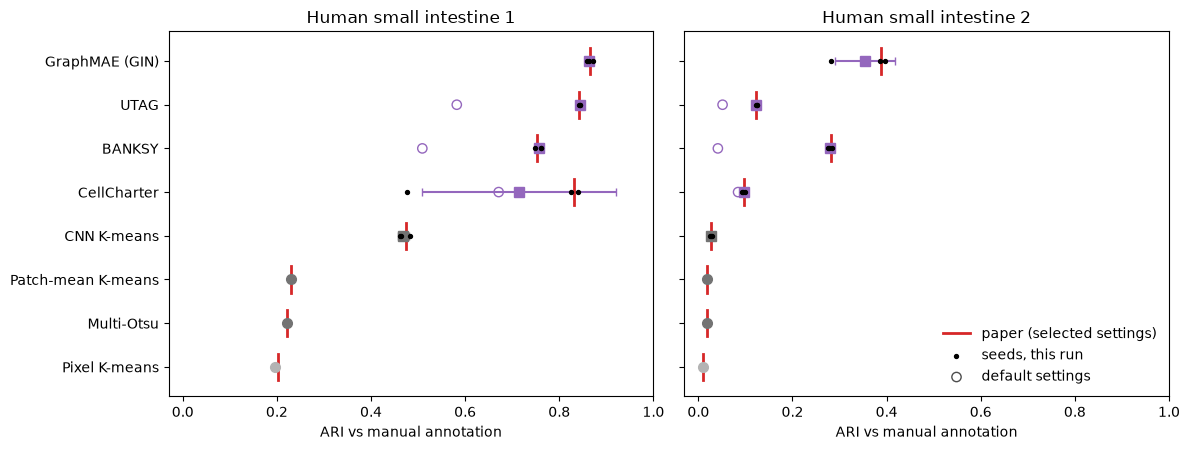

Notebook elapsed: 32.5 min


In [22]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for axis, title in zip(axes, TITLES.values()):
    for position, method in enumerate(METHODS[::-1]):
        ours = c[(c.image == title) & (c.method == method)]
        main = ours[ours.panel != "c, default"]["ARI"].to_numpy()
        default = ours[ours.panel == "c, default"]["ARI"].to_numpy()
        colour = "tab:purple" if position >= 4 else "0.45" if position >= 1 else "0.7"
        axis.errorbar(main.mean(), position, xerr=main.std(ddof=1) if len(main) > 1 else None, color=colour,
                      marker="s" if len(main) > 1 else "o", markersize=7, capsize=3)
        if len(main) > 1:
            axis.scatter(main, np.full(len(main), position), color="black", s=8, zorder=3)
        if len(default):
            axis.scatter(default, [position], facecolors="none", edgecolors=colour, s=45)
        axis.plot([paper_c.loc[(title, method), "ari_mean"]] * 2, [position - 0.3, position + 0.3],
                  color="tab:red", linewidth=2)
    axis.set_yticks(range(len(METHODS)), METHODS[::-1])
    axis.set_xlim(-0.03, 1)
    axis.set_xlabel("ARI vs manual annotation")
    axis.set_title(title)
axes[1].plot([], [], color="tab:red", linewidth=2, label="paper (selected settings)")
axes[1].scatter([], [], color="black", s=8, label="seeds, this run")
axes[1].scatter([], [], facecolors="none", edgecolors="0.3", s=45, label="default settings")
axes[1].legend(frameon=False, loc="lower right")
figure.tight_layout()
plt.show()
print(f"Notebook elapsed: {(time.perf_counter() - STARTED) / 60:.1f} min")

## 6. Paper and notebook results

The table puts every ARI of Figure 2 from the paper beside the value computed in this notebook, for both images.

- **a, b:** the seed drawn in the maps.
- **d:** the mean of five seeds.
- **c, selected settings:** the mean of three seeds; the three intensity baselines are single runs.
- **c, default settings:** single runs.

All models are trained here from scratch on a GPU. The CNN uses adaptive average pooling, which has no
deterministic CUDA implementation in PyTorch, so the values can differ slightly between GPUs and library versions.

In [23]:
selected = c[c.panel != "c, default"].groupby(["image", "method"])["ARI"].mean()
default = c[c.panel == "c, default"].set_index(["image", "method"])["ARI"]

records = []   # panel, method, image, paper, this run
for (key, title), sheet in zip(TITLES.items(), ("a_seeds", "b_seeds")):
    paper_shown = PAPER[sheet].query("shown_in_map").set_index("method")["ari"].to_dict()
    paper_shown["Pixel K-means"] = paper_c.loc[(title, "Pixel K-means"), "ari_mean"]
    records += [("a, b: seed drawn in the maps", method, title, paper_shown[method], score.ari)
                for method, score in shown[key].items()]
    records += [("d: mean of five seeds", method, title, paper_d.loc[(title, method), "mean"],
                 summary_d.loc[(title, method), "mean"]) for method in ORDER_D]
    records += [("c: selected settings", method, title, paper_c.loc[(title, method), "ari_mean"],
                 selected[title, method]) for method in METHODS]
    records += [("c: default settings", method, title, paper_c.loc[(title, method), "ari_default"],
                 default[title, method]) for method in DEFAULTS]

summary = pd.DataFrame(records, columns=["panel", "method", "image", "paper", "this run"])
rows = pd.MultiIndex.from_frame(summary[["panel", "method"]].drop_duplicates())
columns = [(title, source) for title in TITLES.values() for source in ("paper", "this run")]
(summary.pivot(index=["panel", "method"], columns="image", values=["paper", "this run"])
 .swaplevel(axis=1).loc[rows, columns].rename_axis(columns=[None, None]).round(3))

Human small intestine 1  \
                                                                        paper   
panel                        method                                             
a, b: seed drawn in the maps Pixel K-means                              0.203   
                             CNN K-means                                0.447   
                             GraphMAE                                   0.902   
d: mean of five seeds        CNN K-means                                0.451   
                             GraphMAE, shuffled edges                   0.001   
                             GraphMAE, no edges                         0.243   
                             GraphMAE, full graph                       0.897   
c: selected settings         GraphMAE (GIN)                             0.866   
                             UTAG                                       0.842   
                             BANKSY                                     0.753   
                             CellCharter                                0.831   
                             CNN K-means                                0.473   
                             Patch-mean K-means                         0.229   
                             Multi-Otsu                                 0.222   
                             Pixel K-means                              0.203   
c: default settings          BANKSY                                     0.521   
                             UTAG                                       0.582   
                             CellCharter                                0.670   

                                                                \
                                                      this run   
panel                        method                              
a, b: seed drawn in the maps Pixel K-means               0.196   
                             CNN K-means                 0.447   
                             GraphMAE                    0.903   
d: mean of five seeds        CNN K-means                 0.451   
                             GraphMAE, shuffled edges    0.001   
                             GraphMAE, no edges          0.243   
                             GraphMAE, full graph        0.897   
c: selected settings         GraphMAE (GIN)              0.864   
                             UTAG                        0.843   
                             BANKSY                      0.757   
                             CellCharter                 0.714   
                             CNN K-means                 0.469   
                             Patch-mean K-means          0.229   
                             Multi-Otsu                  0.222   
                             Pixel K-means               0.196   
c: default settings          BANKSY                      0.509   
                             UTAG                        0.582   
                             CellCharter                 0.671   

                                                      Human small intestine 2  \
                                                                        paper   
panel                        method                                             
a, b: seed drawn in the maps Pixel K-means                              0.010   
                             CNN K-means                                0.029   
                             GraphMAE                                   0.423   
d: mean of five seeds        CNN K-means                                0.024   
                             GraphMAE, shuffled edges                   0.000   
                             GraphMAE, no edges                         0.039   
                             GraphMAE, full graph                       0.418   
c: selected settings         GraphMAE (GIN)                             0.389   
                             UTAG                                       0.

[Mantpy](https://github.com/moeghaf/Mantpy) · [image 1](https://doi.org/10.5281/zenodo.21538382) ·
[image 2](https://doi.org/10.5281/zenodo.23740311) · [UTAG](https://github.com/ElementoLab/utag) ·
[BANKSY](https://github.com/prabhakarlab/Banksy_py) · [CellCharter](https://cellcharter.readthedocs.io/en/stable/)